# MIMIC-III phenotyping, acq_size=250: when does vendi-q2 help?

**Question.** On the 25-condition multi-label phenotyping task (`mimic3_pheno`), under which settings does
vendi-q2 beat random, which conditions separate the AL methods, and does label imbalance matter?

**Experiment.** SAND model, all cohort, 250 initial labels + 9 rounds x 250 = 2500 labels, 3 seeds
(12345-12347). 5 baselines (random, badge, bald, entropy, kcentergreedy) and 12 vendi-q2 configs =
6 kernel cells (normalization x gamma) x {feature, gradient} embedding, all RBF. This is the non-sequential
`vendi-q2`: each pool stay is scored on its own by its squared kernel similarity to the labelled set,
`sum_l K(x, l)^2`, and the 250 least similar are taken (picks within a batch do not interact;
`query.vendi.batch_size=1` is only read by `vendi-q2-sequential`).
Launchers: `launchers/sweep_exp_mimic3_pheno_250_nograd.py`, `..._250_grad.py`, `..._250_grad_1_minmax.py`.

**Data sources.**
- run list + configs: wandb (`config.data.name = mimic3_pheno`, `config.active.acq_size = 250`)
- per-condition test curves: `misc/phenotype_by_task_results/*.csv` (written by `misc/phenotype_by_task.py`,
  identical to the `al/phenotype/*` keys it pushed to wandb)
- labels of the acquired stays: `stored.npz["added_labels"]` in each run directory
- condition prevalence: `$DATA_ROOT/mimic3_sand/all/train/phenotype.npy`

**Conventions.** Every method shares the same initial labelled set within a seed, so all comparisons are
*paired by seed* against random. "AUBC" = mean test metric over rounds 1-9 (round 0 is identical for all methods).

In [1]:
import ipynb_setup  # adds src/ to sys.path and loads .env
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wandb
from scipy import stats

from data.mimic_dataset import PHENO_CONDITION_NAMES

ROOT = Path("..")
PER_TASK_DIR = ROOT / "misc/phenotype_by_task_results"
RUN_DIRS = ROOT / "experiments/activelearning/mimic3_pheno/active-mimic3_med"
DATA_DIR = Path(os.environ["DATA_ROOT"]) / "mimic3_sand/all"
PROJECT = "jingwusince01-national-taiwan-uni/realistic-al"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

Loading .env from /home/jing/Desktop/realistic-al/.env


## 0. Load data

Run list from wandb. Method names: `vq2-{grad|feat}-{normalization}-{gamma}` for vendi-q2.

In [2]:
def method_name(query):
    if query["name"] != "vendi-q2":
        return query["name"]
    v = query["vendi"]
    emb = "grad" if v["use_grad"] else "feat"
    gamma = "1.0" if str(v["gamma"]) in ("1", "1.0") else str(v["gamma"])[:3]  # median -> med
    return f"vq2-{emb}-{v['normalization']}-{gamma}"


filters = {"config.data.name": "mimic3_pheno", "config.active.acq_size": 250, "state": "finished"}
runs = pd.DataFrame(
    [dict(wandb_id=r.id, seed=r.config["trainer"]["seed"], method=method_name(r.config["query"]))
     for r in wandb.Api().runs(PROJECT, filters=filters)]
)
print(len(runs), "runs")
runs.groupby("method").seed.apply(sorted)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/jing/.netrc.


51 runs


method
badge                  [12345, 12346, 12347]
bald                   [12345, 12346, 12347]
entropy                [12345, 12346, 12347]
kcentergreedy          [12345, 12346, 12347]
random                 [12345, 12346, 12347]
vq2-feat-l2-med        [12345, 12346, 12347]
vq2-feat-minmax-1.0    [12345, 12346, 12347]
vq2-feat-minmax-med    [12345, 12346, 12347]
vq2-feat-none-med      [12345, 12346, 12347]
vq2-feat-zscore-dim    [12345, 12346, 12347]
vq2-feat-zscore-med    [12345, 12346, 12347]
vq2-grad-l2-med        [12345, 12346, 12347]
vq2-grad-minmax-1.0    [12345, 12346, 12347]
vq2-grad-minmax-med    [12345, 12346, 12347]
vq2-grad-none-med      [12345, 12346, 12347]
vq2-grad-zscore-dim    [12345, 12346, 12347]
vq2-grad-zscore-med    [12345, 12346, 12347]
Name: seed, dtype: object

Per-condition test curves (AUROC / AUPRC / F1 / acc for each of the 25 conditions at each round).

In [3]:
files = {f.stem.split("__")[-1]: f for f in PER_TASK_DIR.glob("*.csv")}
curves = pd.concat([pd.read_csv(files[i]) for i in runs.wandb_id])
curves = curves.drop(columns=["settings", "seed"]).merge(runs, on="wandb_id")
curves["cond"] = curves.condition.str[:2].astype(int)
curves[["method", "seed", "n_labelled", "condition", "metric", "value"]].head()

,method,seed,n_labelled,condition,metric,value
0,vq2-grad-none-med,12345,250,00_acute_and_unspecified_renal_fail,auroc,0.772
1,vq2-grad-none-med,12345,250,01_acute_cerebrovascular_disease,auroc,0.813
2,vq2-grad-none-med,12345,250,02_acute_myocardial_infarction,auroc,0.694
3,vq2-grad-none-med,12345,250,03_cardiac_dysrhythmias,auroc,0.690
4,vq2-grad-none-med,12345,250,04_chronic_kidney_disease,auroc,0.784


Condition names and prevalence in the training pool.

In [4]:
y_train = np.load(DATA_DIR / "train/phenotype.npy")
conds = pd.DataFrame({
    "name": [n.split(";")[0].split("(")[0].strip()[:30] for n in PHENO_CONDITION_NAMES],
    "prevalence": y_train.mean(0),
})
print("mean #conditions per stay:", y_train.sum(1).mean().round(2))
conds.sort_values("prevalence")

mean #conditions per stay: 4.67


,name,prevalence
19,Other upper respiratory diseas,0.053
18,Other lower respiratory diseas,0.064
7,Conduction disorders,0.075
1,Acute cerebrovascular disease,0.080
15,Gastrointestinal hemorrhage,0.082
24,Shock,0.096
10,Diabetes mellitus with complic,0.099
17,Other liver diseases,0.112
2,Acute myocardial infarction,0.115
20,Pleurisy,0.116


Labels of the stays each run acquired. `added_labels` has shape (10 acquisitions, 250, 25); the 10th batch is
queried after the last training round, so acquisitions 0-8 = the 2250 acquired labels the final model trains on.

In [5]:
acquired = {}  # wandb_id -> (2250, 25) multi-hot labels of the acquired stays
for run_dir in RUN_DIRS.glob("*/*start-250_step-250*/20*"):
    if (run_dir / "stored.npz").exists() and (run_dir / "wandb/latest-run").exists():
        wandb_id = os.readlink(run_dir / "wandb/latest-run").split("-")[-1]
        acquired[wandb_id] = np.load(run_dir / "stored.npz")["added_labels"][:9].reshape(-1, 25)

acquired = {i: acquired[i] for i in runs.wandb_id}  # keep only the runs that are on wandb
len(acquired)

51

AUBC per (metric, method, seed, condition) and the paired difference to random.

In [6]:
aubc = curves[curves.al_iter >= 1].groupby(["metric", "method", "seed", "cond"]).value.mean().reset_index()
rand = aubc[aubc.method == "random"].drop(columns="method").rename(columns={"value": "random"})
aubc = aubc.merge(rand, on=["metric", "seed", "cond"])
aubc["delta"] = aubc.value - aubc.random

VQ2_GRAD = sorted(m for m in runs.method.unique() if m.startswith("vq2-grad"))
VQ2_FEAT = sorted(m for m in runs.method.unique() if m.startswith("vq2-feat"))
BEST = "vq2-grad-minmax-med"

## 1. Macro view (mean over the 25 conditions)

In [7]:
macro = aubc.groupby(["metric", "method", "seed"]).delta.mean()  # macro delta per seed
macro = macro.groupby(["metric", "method"]).agg(["mean", "std"]).unstack(0)
macro.columns = [f"{metric}_{stat}" for stat, metric in macro.columns]
macro[["auprc_mean", "auprc_std", "auroc_mean", "auroc_std"]].sort_values("auprc_mean", ascending=False)

,auprc_mean,auprc_std,auroc_mean,auroc_std
method,,,,
badge,0.004,3.739e-03,4.592e-04,3.008e-03
random,0.000,0.000e+00,0.000e+00,0.000e+00
vq2-grad-minmax-med,-0.004,3.035e-03,-1.132e-02,1.000e-03
vq2-grad-minmax-1.0,-0.005,8.987e-04,-1.176e-02,1.674e-03
vq2-grad-l2-med,-0.006,2.722e-03,-6.813e-03,1.687e-03
vq2-grad-none-med,-0.007,1.486e-03,-1.297e-02,1.582e-03
vq2-grad-zscore-dim,-0.009,7.187e-04,-1.598e-02,1.482e-03
vq2-feat-l2-med,-0.009,8.916e-04,-1.542e-02,1.840e-03
entropy,-0.010,3.357e-03,-1.056e-02,1.103e-03


In [8]:
for name, methods in [("vq2 grad", VQ2_GRAD), ("vq2 feat", VQ2_FEAT)]:
    x = aubc[aubc.method.isin(methods)].groupby("metric").delta.mean()
    print(f"{name}: mean delta vs random  AUPRC {x['auprc']:+.4f}   AUROC {x['auroc']:+.4f}")

# grad vs feat, per condition, matched by kernel cell
g = aubc[aubc.method.isin(VQ2_GRAD)].assign(cell=lambda d: d.method.str[9:]).groupby(["metric", "cond", "cell"]).value.mean()
f = aubc[aubc.method.isin(VQ2_FEAT)].assign(cell=lambda d: d.method.str[9:]).groupby(["metric", "cond", "cell"]).value.mean()
print("fraction of (condition, kernel cell) pairs where grad > feat:", ((g - f) > 0).groupby("metric").mean().round(2).to_dict())

vq2 grad: mean delta vs random  AUPRC -0.0069   AUROC -0.0125
vq2 feat: mean delta vs random  AUPRC -0.0159   AUROC -0.0192
fraction of (condition, kernel cell) pairs where grad > feat: {'acc': 0.83, 'auprc': 0.81, 'auroc': 0.83, 'f1': 0.63}


Only badge matches random on the macro metric. Every vendi-q2 config is below random, and the gradient
embedding beats the feature embedding almost everywhere. The macro number hides a lot, though: see the
per-condition view.

## 2. Per-condition: where does vendi-q2 win?

`vq2_grad` = mean over the 6 gradient configs (avoids picking the best config per condition after the fact);
`t` = paired t-statistic over the 3 seeds.

In [9]:
def per_cond(metric, methods):
    x = aubc[(aubc.metric == metric) & aubc.method.isin(methods)]
    return x.groupby(["cond", "seed"]).delta.mean().groupby("cond")


table = conds.assign(
    auprc_vq2_grad=per_cond("auprc", VQ2_GRAD).mean(),
    t=per_cond("auprc", VQ2_GRAD).agg(lambda s: s.mean() / (s.std() / np.sqrt(len(s)))),
    auprc_best_cfg=per_cond("auprc", [BEST]).mean(),
    auprc_badge=per_cond("auprc", ["badge"]).mean(),
    auroc_vq2_grad=per_cond("auroc", VQ2_GRAD).mean(),
    auroc_badge=per_cond("auroc", ["badge"]).mean(),
)
table.sort_values("auprc_vq2_grad", ascending=False)

,name,prevalence,auprc_vq2_grad,t,auprc_best_cfg,auprc_badge,auroc_vq2_grad,auroc_badge
17,Other liver diseases,0.112,0.022,4.900,0.029,1.666e-02,1.864e-03,3.091e-03
24,Shock,0.096,0.018,2.431,0.022,5.970e-03,2.047e-03,2.644e-03
22,Respiratory failure,0.274,0.011,6.843,0.019,1.365e-02,-3.076e-03,2.437e-03
3,Cardiac dysrhythmias,0.359,0.008,2.216,0.007,8.175e-04,3.345e-03,1.352e-03
7,Conduction disorders,0.075,0.007,1.438,0.010,1.001e-02,-3.067e-03,5.168e-03
0,Acute and unspecified renal fa,0.255,0.006,3.184,0.011,6.371e-03,-8.569e-03,-6.309e-04
8,Congestive heart failure,0.301,0.005,2.789,0.011,1.681e-02,-8.323e-03,3.195e-03
6,Complications of surgical proc,0.267,0.005,3.073,0.009,1.701e-03,-3.201e-04,-1.047e-03
23,Septicemia,0.178,0.003,0.436,0.008,9.036e-03,-6.211e-03,3.241e-04
10,Diabetes mellitus with complic,0.099,-0.002,-0.158,0.006,1.774e-02,-1.453e-02,6.067e-03


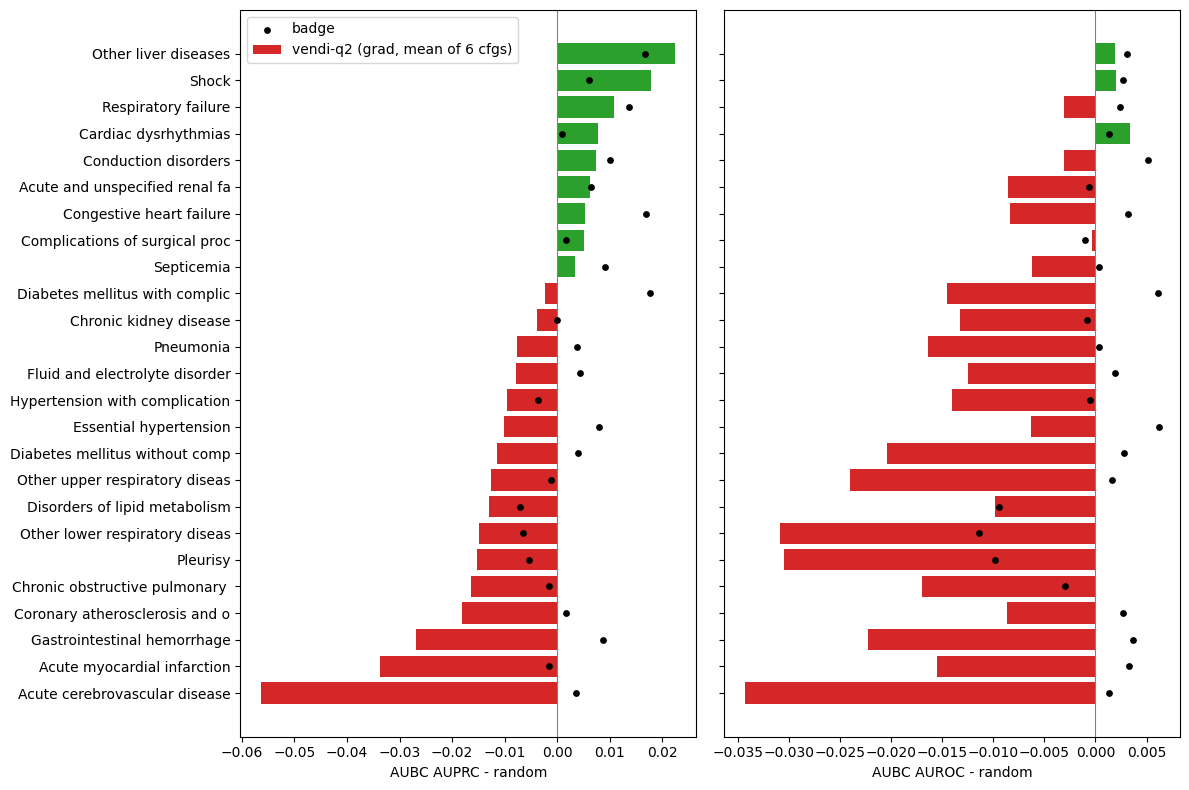

In [10]:
t = table.sort_values("auprc_vq2_grad")
fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)
for ax, metric in zip(axes, ["auprc", "auroc"]):
    ax.barh(t.name, t[f"{metric}_vq2_grad"], color=np.where(t[f"{metric}_vq2_grad"] > 0, "tab:green", "tab:red"),
            label="vendi-q2 (grad, mean of 6 cfgs)")
    ax.scatter(t[f"{metric}_badge"], t.name, color="k", zorder=3, s=15, label="badge")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel(f"AUBC {metric.upper()} - random")
axes[0].legend(loc="upper left")
plt.tight_layout()

vendi-q2 wins AUPRC on a coherent group of **acute, severity-driven conditions**: liver disease, shock,
respiratory failure, renal failure, septicemia, cardiac dysrhythmias. On most of them the best config
(`vq2-grad-minmax-med`) also beats badge. It loses on chronic comorbidities (hypertension, lipids, coronary, COPD) and on
cerebrovascular disease / AMI / GI hemorrhage. On AUROC the wins are marginal (<= +0.003).

## 3. Why: what does vendi-q2 actually label?

### 3a. It labels sicker patients

In [11]:
n_cond = pd.Series({i: a.sum(1).mean() for i, a in acquired.items()}, name="n_cond")
print("population mean #conditions per stay:", y_train.sum(1).mean().round(2))
runs.join(n_cond, on="wandb_id").groupby("method").n_cond.mean().sort_values()

population mean #conditions per stay: 4.67


method
random                 4.657
vq2-feat-minmax-med    4.833
badge                  5.019
vq2-feat-none-med      5.287
vq2-feat-zscore-med    5.287
vq2-feat-zscore-dim    5.375
vq2-feat-minmax-1.0    5.579
bald                   5.732
kcentergreedy          5.753
entropy                5.912
vq2-feat-l2-med        6.043
vq2-grad-none-med      6.061
vq2-grad-minmax-1.0    6.206
vq2-grad-minmax-med    6.218
vq2-grad-l2-med        6.280
vq2-grad-zscore-med    6.435
vq2-grad-zscore-dim    6.437
Name: n_cond, dtype: float64

### 3b. Which conditions it over-/under-samples
`enrich` = positives acquired for a condition / positives random acquired (same seed).
`atyp` = mean #conditions of the acquired positives / mean #conditions of all training positives of that
condition (> 1: the positives picked are more multi-morbid than a typical positive).

In [12]:
typical = np.array([y_train[y_train[:, c] == 1].sum(1).mean() for c in range(25)])

rows = []
for wandb_id, a in acquired.items():
    for c in range(25):
        positives = a[a[:, c] == 1]
        rows.append(dict(wandb_id=wandb_id, cond=c, n_pos=len(positives),
                         atyp=positives.sum(1).mean() / typical[c]))
pos = pd.DataFrame(rows).merge(runs, on="wandb_id")
rand_pos = pos[pos.method == "random"][["seed", "cond", "n_pos"]].rename(columns={"n_pos": "random_pos"})
pos = pos.merge(rand_pos, on=["seed", "cond"])
pos["enrich"] = pos.n_pos / pos.random_pos

enrich = pos.groupby(["cond", "method"]).enrich.mean().unstack()
show = ["entropy", "bald", "kcentergreedy", BEST, "vq2-grad-l2-med", "vq2-feat-minmax-med"]
conds[["name", "prevalence"]].join(enrich[show]).sort_values(BEST, ascending=False)

,name,prevalence,entropy,bald,kcentergreedy,vq2-grad-minmax-med,vq2-grad-l2-med,vq2-feat-minmax-med
24,Shock,0.096,1.061,2.524,2.979,2.789,1.297,2.167
17,Other liver diseases,0.112,1.044,2.145,2.676,2.049,0.726,1.767
23,Septicemia,0.178,1.545,1.664,1.996,1.876,1.254,1.439
22,Respiratory failure,0.274,1.161,1.717,1.883,1.860,1.487,1.467
0,Acute and unspecified renal fa,0.255,1.611,1.718,1.888,1.859,1.549,1.483
4,Chronic kidney disease,0.148,1.894,1.349,1.257,1.620,1.848,1.158
10,Diabetes mellitus with complic,0.099,1.282,1.743,1.591,1.573,1.222,1.856
15,Gastrointestinal hemorrhage,0.082,1.491,1.319,1.443,1.567,0.857,1.185
16,Hypertension with complication,0.142,1.776,1.291,1.180,1.539,1.760,1.184
14,Fluid and electrolyte disorder,0.321,1.270,1.463,1.571,1.527,1.193,1.373


In [13]:
rho = lambda a, b: stats.spearmanr(a, b)[0]
print(f"enrichment profile similarity (Spearman over conditions):")
print(f"  {BEST} vs kcentergreedy : {rho(enrich[BEST], enrich['kcentergreedy']):+.2f}")
print(f"  vq2-grad-l2-med vs entropy   : {rho(enrich['vq2-grad-l2-med'], enrich['entropy']):+.2f}")
print(f"  vq2-grad-l2-med vs {BEST}: {rho(enrich['vq2-grad-l2-med'], enrich[BEST]):+.2f}")

# how visible a condition is in the first 24h: random's AUROC with only the 250 initial labels
init_auroc = curves[(curves.metric == "auroc") & (curves.al_iter == 0)].groupby("cond").value.mean()
print(f"\n{BEST} enrichment vs prevalence       : {rho(enrich[BEST], conds.prevalence):+.2f}")
print(f"{BEST} enrichment vs 24h visibility   : {rho(enrich[BEST], init_auroc):+.2f}  (init AUROC of random)")

enrichment profile similarity (Spearman over conditions):
  vq2-grad-minmax-med vs kcentergreedy : +0.94
  vq2-grad-l2-med vs entropy   : +0.74
  vq2-grad-l2-med vs vq2-grad-minmax-med: -0.05

vq2-grad-minmax-med enrichment vs prevalence       : -0.12
vq2-grad-minmax-med enrichment vs 24h visibility   : +0.61  (init AUROC of random)


vendi-q2 with minmax/none/zscore normalization picks the same conditions as kcentergreedy: diversity in the
SAND embedding = the physiological periphery = the sickest stays. What it over-samples follows how visible a
condition is in the first-24h data, **not** how rare it is. The L2-normalised gradient variant is different:
L2 removes the gradient magnitude (the uncertainty part of the BADGE-style embedding), and its profile looks
like entropy instead.

### 3c. More (and typical) positives -> better AUPRC

In [14]:
cells = aubc[(aubc.metric == "auprc") & (aubc.method != "random")].groupby(["method", "cond"]).delta.mean()
cells = pd.concat([cells, pos.groupby(["method", "cond"])[["enrich", "atyp"]].mean()], axis=1, join="inner").reset_index()

within = [rho(g.delta, g.enrich) for _, g in cells.groupby("cond")]
print(f"within a condition, across methods: rho(delta AUPRC, enrichment) median {np.median(within):+.2f}, "
      f"positive in {np.sum(np.array(within) > 0)}/25 conditions")

X = np.column_stack([np.ones(len(cells)), np.log(cells.enrich), cells.atyp - 1])
coef, *_ = np.linalg.lstsq(X, cells.delta, rcond=None)
r2 = 1 - np.var(cells.delta - X @ coef) / np.var(cells.delta)
print(f"pooled OLS over {len(cells)} (method, condition) cells: "
      f"dAUPRC = {coef[0]:+.4f} {coef[1]:+.4f}*log(enrich) {coef[2]:+.4f}*(atyp-1)   R2 = {r2:.2f}")

conds[["name"]].join(pos[pos.method == BEST].groupby("cond")[["enrich", "atyp"]].mean()).join(
    table.auprc_best_cfg).sort_values("auprc_best_cfg")

within a condition, across methods: rho(delta AUPRC, enrichment) median +0.55, positive in 23/25 conditions
pooled OLS over 400 (method, condition) cells: dAUPRC = -0.0082 +0.0225*log(enrich) -0.0467*(atyp-1)   R2 = 0.25


,name,enrich,atyp,auprc_best_cfg
1,Acute cerebrovascular disease,1.157,1.301,-0.055
2,Acute myocardial infarction,1.143,1.210,-0.041
15,Gastrointestinal hemorrhage,1.567,1.230,-0.029
18,Other lower respiratory diseas,1.046,1.199,-0.018
20,Pleurisy,1.264,1.197,-0.017
12,Disorders of lipid metabolism,0.845,1.312,-0.014
9,Coronary atherosclerosis and o,0.896,1.278,-0.014
19,Other upper respiratory diseas,1.124,1.227,-0.013
11,Diabetes mellitus without comp,1.114,1.200,-0.009
5,Chronic obstructive pulmonary,1.045,1.205,-0.008


Two ingredients decide the per-condition result: labelling **more** positives helps, and labelling
**atypical** positives hurts. Cerebrovascular disease is the clearest loss: vendi-q2 does not under-sample it,
but the stroke patients it picks carry ~30% more comorbidities than a typical stroke patient, so the model
learns "stroke + multi-organ failure" while most test positives look physiologically unremarkable.

## 4. Which conditions separate the methods?

In [15]:
def separation(metric):
    a = aubc[aubc.metric == metric]
    means = a.groupby(["cond", "method"]).value.mean().unstack()
    r = curves[(curves.metric == metric) & (curves.method == "random")]
    return conds[["name", "prevalence"]].assign(
        spread=means.max(1) - means.min(1),                             # best minus worst method
        noise=a[a.method != "random"].groupby(["cond", "method"]).delta.std().groupby("cond").mean(),  # seed noise
        headroom=r[r.al_iter == 9].groupby("cond").value.mean() - r[r.al_iter == 0].groupby("cond").value.mean(),
    ).assign(snr=lambda d: d.spread / d.noise)


for metric in ["auroc", "auprc"]:
    s = separation(metric)
    print(metric, " ".join(f"rho(spread,{k})={rho(s.spread, s[k]):+.2f}" for k in ["headroom", "noise", "prevalence"]),
          f"| rho(snr,headroom)={rho(s.snr, s.headroom):+.2f}")
sep = separation("auroc")
sep.sort_values("spread", ascending=False)

auroc rho(spread,headroom)=+0.84 rho(spread,noise)=+0.72 rho(spread,prevalence)=-0.58 | rho(snr,headroom)=+0.09
auprc rho(spread,headroom)=+0.81 rho(spread,noise)=+0.66 rho(spread,prevalence)=-0.36 | rho(snr,headroom)=+0.14


,name,prevalence,spread,noise,headroom,snr
19,Other upper respiratory diseas,0.053,0.072,0.015,0.108,4.678
15,Gastrointestinal hemorrhage,0.082,0.047,0.006,0.107,7.648
18,Other lower respiratory diseas,0.064,0.046,0.015,0.063,3.124
1,Acute cerebrovascular disease,0.080,0.044,0.010,0.071,4.228
11,Diabetes mellitus without comp,0.196,0.041,0.005,0.110,7.447
5,Chronic obstructive pulmonary,0.137,0.040,0.010,0.080,4.131
16,Hypertension with complication,0.142,0.039,0.007,0.086,5.666
10,Diabetes mellitus with complic,0.099,0.039,0.015,0.099,2.597
20,Pleurisy,0.116,0.038,0.007,0.070,5.573
13,Essential hypertension,0.413,0.037,0.005,0.052,7.073


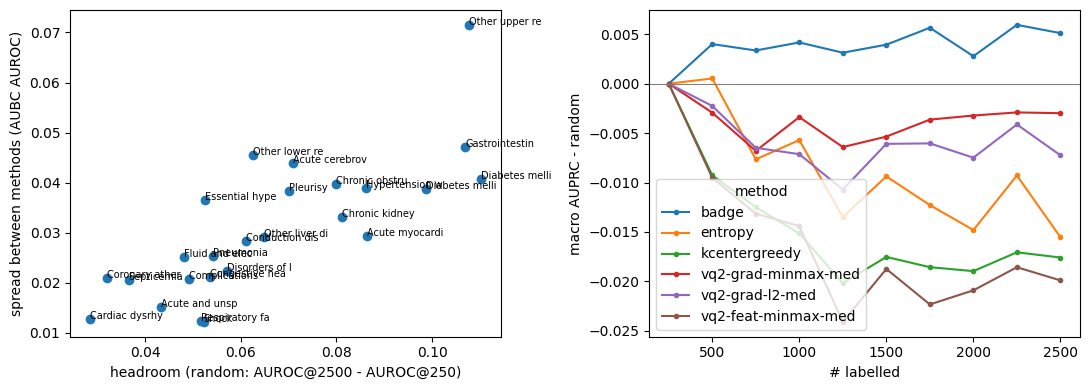

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(sep.headroom, sep.spread)
for _, r in sep.iterrows():
    axes[0].annotate(r["name"][:14], (r.headroom, r.spread), fontsize=7)
axes[0].set(xlabel="headroom (random: AUROC@2500 - AUROC@250)", ylabel="spread between methods (AUBC AUROC)")

x = curves[curves.metric == "auprc"]
x = x.merge(x[x.method == "random"][["seed", "cond", "al_iter", "value"]].rename(columns={"value": "random"}),
            on=["seed", "cond", "al_iter"])
gap = (x.value - x.random).groupby([x.method, x.n_labelled]).mean().unstack(0)
gap[["badge", "entropy", "kcentergreedy", BEST, "vq2-grad-l2-med", "vq2-feat-minmax-med"]].plot(ax=axes[1], marker=".")
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set(xlabel="# labelled", ylabel="macro AUPRC - random")
plt.tight_layout()

The absolute gap between methods is largest where the learning curve still climbs (rare-ish, hard conditions:
upper/lower respiratory, GI hemorrhage, cerebrovascular, diabetes) and smallest where the model is already good
with 250 labels (shock, respiratory failure, dysrhythmias). But seed noise grows just as fast, so the
signal-to-noise ratio (spread / seed noise, ~3-8) is uncorrelated with headroom. The spread is mostly *downward* (diversity methods falling
below random), and the gaps open by ~500-750 labels and then stay constant.

## 5. Does label imbalance matter?

Prevalence is confounded with headroom (rare conditions tend to have more headroom), so we also report the rank
correlation with prevalence *after* partialling out headroom.

In [17]:
def partial_rho(x, y, z):
    rx, ry, rz = stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)
    resid = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    return stats.pearsonr(resid(rx), resid(ry))


for metric in ["auprc", "auroc"]:
    s = separation(metric)
    for col in [f"{metric}_vq2_grad", f"{metric}_badge"]:
        r, p = stats.spearmanr(conds.prevalence, table[col])
        pr, pp = partial_rho(conds.prevalence, table[col], s.headroom)
        print(f"{col:16s} vs prevalence: rho={r:+.2f} (p={p:.2f})   | headroom partialled out: {pr:+.2f} (p={pp:.2f})")
r, p = stats.spearmanr(conds.prevalence, enrich[BEST])
print(f"\n{BEST} enrichment vs prevalence: rho={r:+.2f} (p={p:.2f})")

auprc_vq2_grad   vs prevalence: rho=+0.20 (p=0.34)   | headroom partialled out: +0.16 (p=0.46)
auprc_badge      vs prevalence: rho=+0.08 (p=0.70)   | headroom partialled out: +0.15 (p=0.48)
auroc_vq2_grad   vs prevalence: rho=+0.47 (p=0.02)   | headroom partialled out: +0.06 (p=0.76)
auroc_badge      vs prevalence: rho=+0.00 (p=0.99)   | headroom partialled out: +0.12 (p=0.56)

vq2-grad-minmax-med enrichment vs prevalence: rho=-0.12 (p=0.56)


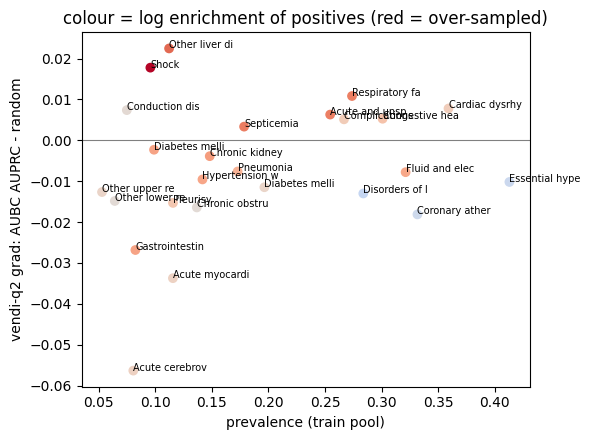

In [18]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(table.prevalence, table.auprc_vq2_grad, c=np.log(enrich[BEST]), cmap="coolwarm", vmin=-1, vmax=1)
for _, r in table.iterrows():
    ax.annotate(r["name"][:14], (r.prevalence, r.auprc_vq2_grad), fontsize=7)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="prevalence (train pool)", ylabel="vendi-q2 grad: AUBC AUPRC - random",
       title="colour = log enrichment of positives (red = over-sampled)")
plt.tight_layout()

Winners and losers both span the whole prevalence range: shock (10%) and liver (11%) win, cerebrovascular (8%)
and GI hemorrhage (8%) lose; dysrhythmias (36%) and respiratory failure (27%) win, hypertension (41%) and
coronary disease (33%) lose. Within the AUPRC result, prevalence has no significant relation to the vendi-q2 gain,
and vendi-q2 does not preferentially sample rare conditions. The colour (enrichment) separates winners from
losers much better than the x-axis (prevalence).

## 6. How vendi-q2 (grad, rbf-median, L2) finds more positives

Moved to its own notebook: [mimic3_pheno_250_vendi_l2_positives.ipynb](mimic3_pheno_250_vendi_l2_positives.ipynb).

## Takeaways

**When does vendi-q2 perform well?** When the diversity direction of the embedding lines up with the label you
care about. On this task that happens only for a subset of labels:

1. **Embedding: gradient, not feature.** Grad beats feat in ~81% of (condition, kernel cell) pairs; macro
   AUPRC -0.007 vs -0.016 relative to random. Normalization `minmax`/`none` with median bandwidth gives the AUPRC wins;
   `l2` strips the gradient magnitude and behaves like entropy (best vendi-q2 on AUROC, but loses the acute wins).
2. **Label: positives that stand out in the model's representation.** For conditions that are strongly visible in
   the first 24h of physiology (acute organ failure: liver, shock, respiratory failure, renal failure, septicemia),
   vendi-q2 labels 1.9-2.8x more positives than random, and those positives are typical. There it beats random by
   +0.01 to +0.03 AUPRC and beats badge on most of them.
3. **Metric: AUPRC, not AUROC.** More positives improves the ranking of positives; AUROC gains are <= +0.003.
4. **It fails** when the label is a background / chronic comorbidity (hypertension, lipids, coronary, COPD: these
   sit in the dense centre of the embedding and get under-sampled), or when the label is heterogeneous so the
   peripheral positives it picks are atypical (cerebrovascular, AMI, GI hemorrhage: acquired positives 21-30% more
   comorbid than typical).
5. **Macro metric: below random**, because only ~6-9 of 25 labels are aligned with the severity axis.
6. **Budget:** gaps are set by ~500-750 labels and stay constant up to 2500. There is no late catch-up.

**Does label imbalance matter?** Not on its own.
- The vendi-q2 AUPRC gain does not track prevalence (rho +0.20, p=0.34). The AUROC correlation (+0.47, p=0.02)
  disappears once learning-curve headroom is controlled for (+0.06): rarer conditions simply have more headroom.
- vendi-q2 does not preferentially sample rare conditions (enrichment vs prevalence rho -0.12). What it samples is
  set by 24h visibility / severity (rho +0.61).
- Rarity matters only indirectly: rare conditions have more headroom, so methods spread more there, mostly
  because the diversity methods fall below random.
- Contrast with CIFAR-10-imb, where vendi wins: in single-label imbalance the rare classes are separate modes in
  feature space, so "diverse" = "rare". In this multi-label task each stay has ~4.7 labels, imbalance is per-label
  binary, and distance in the embedding encodes illness severity rather than any one label.

**Caveats.** 3 seeds, one budget (250 step), all cohort only, no plain `vendi` (q=1) runs at 250. Per-label
prevalence spans 5-41%, so extreme imbalance (< 5%) is untested. The severity reading is inferred from label
co-occurrence and random's initial AUROC, not from inspecting the embeddings.